# Vendas de sorvete e temperatura

**Pergunta:** quanto a temperatura explica as vendas, e dá para estimar a venda de um dia a partir dela?

A base tem 500 registros, cada um com uma temperatura e uma venda. O projeto original tratava a temperatura como Fahrenheit. Como ela vai de 0 a 45, com média de 22, Celsius é a leitura mais plausível, mas a unidade não está documentada.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

sns.set_style('whitegrid')
SEMENTE = 42

## 1. Carga e qualidade dos dados

In [2]:
dados = pd.read_csv('IceCreamData.csv').rename(columns={'Temperature': 'temperatura', 'Revenue': 'vendas'})
print(f'{len(dados)} linhas, {dados.duplicated().sum()} duplicadas, {dados.isna().sum().sum()} valores ausentes')
dados.describe().round(2)

500 linhas, 0 duplicadas, 0 valores ausentes


,temperatura,vendas
count,500.00,500.00
mean,22.23,521.57
std,8.10,175.40
min,0.00,10.00
25%,17.12,405.56
50%,22.39,529.37
75%,27.74,642.26
max,45.00,1000.00


Os extremos são valores redondos (temperatura de 0 e 45, vendas de 10 e 1.000), e cada um aparece uma única vez. Isso e a correlação muito alta sugerem uma base didática, e não vendas reais.

In [3]:
faixas = pd.cut(dados['temperatura'], [0, 10, 15, 20, 25, 30, 35, 45], include_lowest=True)
resumo = dados.groupby(faixas, observed=True)['vendas'].agg(registros='count', venda_media='mean').round(0)
print(f"Correlação: {dados['temperatura'].corr(dados['vendas']):.3f}")
resumo

Correlação: 0.990


,registros,venda_media
temperatura,,
"(-0.001, 10.0]",40,201.0
"(10.0, 15.0]",55,312.0
"(15.0, 20.0]",99,429.0
"(20.0, 25.0]",116,529.0
"(25.0, 30.0]",111,630.0
"(30.0, 35.0]",48,728.0
"(35.0, 45.0]",31,867.0


## 2. Modelo de regressão linear

20% dos dados ficam fora do treino para medir o erro. A média das vendas serve de comparação: um modelo útil precisa errar menos do que ela.

In [4]:
X = dados[['temperatura']]
y = dados['vendas']
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)

modelo = LinearRegression().fit(X_treino, y_treino)
previsto = modelo.predict(X_teste)
referencia = [y_treino.mean()] * len(y_teste)

print(f'Vendas = {modelo.intercept_:.1f} + {modelo.coef_[0]:.1f} x temperatura')
print(f'R²: {r2_score(y_teste, previsto):.3f}')
print(f'MAE: {mean_absolute_error(y_teste, previsto):.1f} (média como referência: {mean_absolute_error(y_teste, referencia):.1f})')
print(f'RMSE: {root_mean_squared_error(y_teste, previsto):.1f} (média como referência: {root_mean_squared_error(y_teste, referencia):.1f})')

Vendas = 46.8 + 21.4 x temperatura
R²: 0.977
MAE: 19.2 (média como referência: 132.9)
RMSE: 25.5 (média como referência: 169.4)


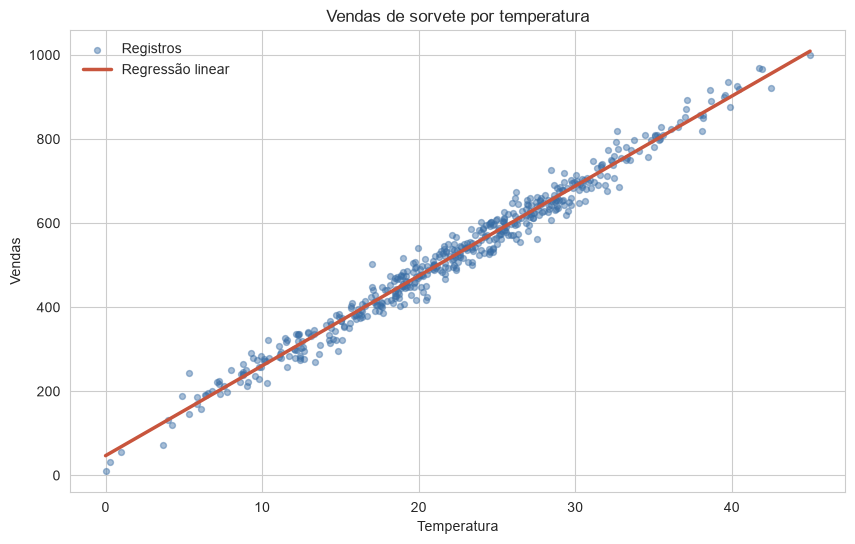

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(dados['temperatura'], dados['vendas'], color='#3a6ea5', alpha=0.45, s=18, label='Registros')
linha = pd.DataFrame({'temperatura': [dados['temperatura'].min(), dados['temperatura'].max()]})
ax.plot(linha['temperatura'], modelo.predict(linha), color='#c8553d', linewidth=2.5, label='Regressão linear')
ax.set_title('Vendas de sorvete por temperatura')
ax.set_xlabel('Temperatura')
ax.set_ylabel('Vendas')
ax.legend(frameon=False)
fig.savefig('imagens/regressao.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Validação

A validação cruzada confere se o resultado depende da divisão escolhida, e testa se uma curva supera a reta.

In [6]:
divisoes = KFold(5, shuffle=True, random_state=SEMENTE)
comparacao = {
    grau: cross_val_score(
        make_pipeline(PolynomialFeatures(grau, include_bias=False), LinearRegression()),
        X, y, cv=divisoes, scoring='r2',
    ).mean().round(4)
    for grau in (1, 2, 3)
}
pd.Series(comparacao, name='R² médio', dtype=float).rename_axis('grau do polinômio')

grau do polinômio
1    0.9792
2    0.9792
3    0.9792
Name: R² médio, dtype: float64

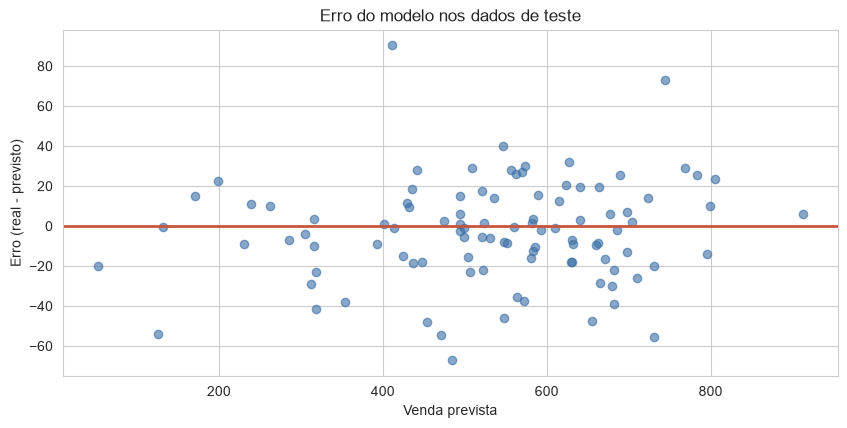

In [7]:
residuos = y_teste - previsto
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(previsto, residuos, color='#3a6ea5', alpha=0.6)
ax.axhline(0, color='#c8553d', linewidth=2)
ax.set_title('Erro do modelo nos dados de teste')
ax.set_xlabel('Venda prevista')
ax.set_ylabel('Erro (real - previsto)')
fig.savefig('imagens/residuos.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Conclusões

- **Relação:** temperatura e vendas têm correlação de 0,99. Cada grau a mais soma cerca de 21,4 em vendas.
- **Qualidade:** nos dados de teste, o R² foi de 0,977 e o erro médio absoluto, de 19,2. Usando apenas a média, esse erro seria de 132,9.
- **Simplicidade:** curvas de grau 2 e 3 não superam a reta (R² médio de 0,979 nos três casos), então a reta é a melhor escolha.

**Limites:** a temperatura é a única variável, e o resultado mostra associação, não causa. Preço, dia da semana e localização não estão na base. O modelo não deve ser usado fora da faixa observada, e um ajuste tão bom é pouco comum em vendas reais.